# Clasificación de flores con una Red Neuronal Convolucional (CNN)
**Actividad:** CNN + Streamlit · **Framework:** TensorFlow / Keras

**Objetivo.** Construir, entrenar y evaluar una CNN que clasifique fotografías de flores en 5 categorías, guardar el modelo y consumirlo desde una aplicación Streamlit.

**Contenido del notebook**
1. Selección y descripción del dataset
2. Exploración y visualización de las imágenes
3. Preprocesamiento, normalización y división train / val / test
4. Data Augmentation
5. Construcción de la CNN
6. Entrenamiento
7. Gráficas del entrenamiento
8. Evaluación con métricas apropiadas
9. Predicciones con imágenes (≥ 10)
10. Guardado del modelo
11. Conclusiones

> **Antes de ejecutar en Colab:** *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU*, y luego *Ejecutar todo*.

## 1. Selección y descripción del dataset

Se usa el dataset **flower_photos**, publicado por el equipo de TensorFlow, con fotografías de flores organizadas en una carpeta por clase:

| Clase (carpeta) | Nombre en español |
|---|---|
| `daisy` | Margarita |
| `dandelion` | Diente de león |
| `roses` | Rosa |
| `sunflowers` | Girasol |
| `tulips` | Tulipán |

**¿Por qué este dataset?**
- Es un problema de **clasificación multiclase (5 clases)** con fotos reales, no imágenes diminutas ni sintéticas.
- Es lo bastante **pequeño** como para que el **Data Augmentation** sea realmente necesario (riesgo de sobreajuste).
- Las imágenes tienen **tamaños y proporciones variables**, lo que justifica un paso de redimensionado.
- Las fotos vienen de cualquier tipo de cámara, así que una app donde el usuario sube una foto propia es un caso de uso realista.

El número exacto de imágenes por clase se calcula en la sección 2 (no está escrito a mano). El archivo descargado incluye un `LICENSE.txt` con los créditos de las imágenes.

In [1]:
import os, json, random, zipfile, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED); np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("Python     :", sys.version.split()[0])
print("TensorFlow :", tf.__version__)
print("Keras      :", keras.__version__)
print("GPU        :", tf.config.list_physical_devices("GPU") or "no detectada (se usará CPU: será lento)")

Python     : 3.13.15
TensorFlow : 2.21.0
Keras      : 3.13.2
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# ---------------- Configuración (idéntica a src/config.py) ----------------
DATASET_URL = ("https://storage.googleapis.com/download.tensorflow.org/"
               "example_images/flower_photos.tgz")
IMG_SIZE   = (180, 180)
BATCH_SIZE = 32
EPOCHS     = 40
LEARNING_RATE = 1e-3
VAL_FRAC, TEST_FRAC = 0.15, 0.15     # => 70 % train / 15 % val / 15 % test

# Rutas: en Colab se trabaja en /content; si se ejecuta desde notebooks/ se usa la raíz del repo
BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR    = BASE / "data"
MODELS_DIR  = BASE / "models"
REPORTS_DIR = BASE / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
for d in (DATA_DIR, MODELS_DIR, FIGURES_DIR):
    d.mkdir(parents=True, exist_ok=True)

MODEL_PATH       = MODELS_DIR / "flower_cnn.keras"
CLASS_NAMES_PATH = MODELS_DIR / "class_names.json"
print("Directorio de trabajo:", BASE)

Directorio de trabajo: /content


In [3]:
# Descarga y descompresión del dataset
def has_images(d):
    return any(True for _ in d.glob("*.jpg")) or any(True for _ in d.glob("*.jpeg"))

def find_dataset_root(base):
    # Busca la carpeta con las subcarpetas de clase (tolera extracciones anidadas)
    base = Path(base)
    for cand in [base, *sorted(p for p in base.rglob("*") if p.is_dir())]:
        classes = [d for d in cand.iterdir() if d.is_dir() and has_images(d)]
        if len(classes) >= 2:
            return cand
    raise RuntimeError(f"No se encontraron carpetas de clase con imágenes dentro de {base}. "
                       "Borra la carpeta 'data' y vuelve a ejecutar esta celda.")

extracted = tf.keras.utils.get_file(
    fname="flower_photos", origin=DATASET_URL, untar=True,
    cache_dir=str(DATA_DIR), cache_subdir="")
ROOT = find_dataset_root(extracted if Path(extracted).is_dir() else DATA_DIR)
print("Dataset en:", ROOT)

class_names = sorted(d.name for d in ROOT.iterdir() if d.is_dir() and has_images(d))
paths, labels = [], []
for idx, name in enumerate(class_names):
    files = sorted(list((ROOT / name).glob("*.jpg")) + list((ROOT / name).glob("*.jpeg")))
    print(f"  {name:<12}: {len(files)} imágenes")
    for p in files:
        paths.append(str(p)); labels.append(idx)
paths, labels = np.array(paths), np.array(labels, dtype="int32")
NUM_CLASSES = len(class_names)
print(f"Clases ({NUM_CLASSES}):", class_names)
print("Total de imágenes:", len(paths))

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Dataset en: /content/data/flower_photos/flower_photos
  daisy       : 633 imágenes
  dandelion   : 898 imágenes
  roses       : 641 imágenes
  sunflowers  : 699 imágenes
  tulips      : 799 imágenes
Clases (5): ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Total de imágenes: 3670


## 2. Exploración y visualización de las imágenes
Se revisa: (a) balance de clases, (b) ejemplos visuales, (c) tamaños de las imágenes, (d) integridad de los archivos y (e) estadísticas de píxeles.

,n_imagenes,porcentaje
daisy,633,17.2
dandelion,898,24.5
roses,641,17.5
sunflowers,699,19.0
tulips,799,21.8


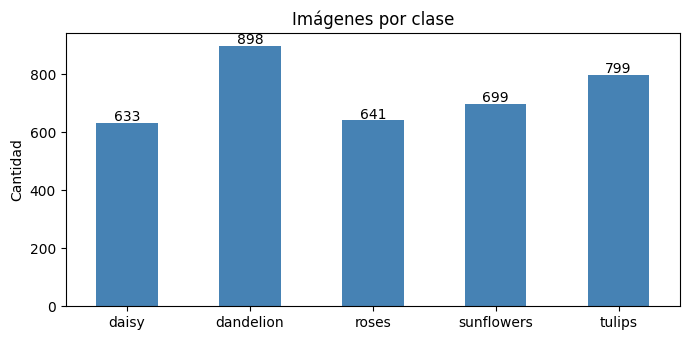

In [4]:
# (a) Balance de clases
counts = pd.Series(labels).map(dict(enumerate(class_names))).value_counts().reindex(class_names)
display(counts.rename("n_imagenes").to_frame().assign(porcentaje=lambda d: (d.n_imagenes / d.n_imagenes.sum() * 100).round(1)))

ax = counts.plot(kind="bar", figsize=(7, 3.5), color="steelblue", rot=0)
ax.set_title("Imágenes por clase"); ax.set_ylabel("Cantidad")
for i, v in enumerate(counts.values):
    ax.text(i, v + 5, str(v), ha="center")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "distribucion_clases.png", dpi=150); plt.show()

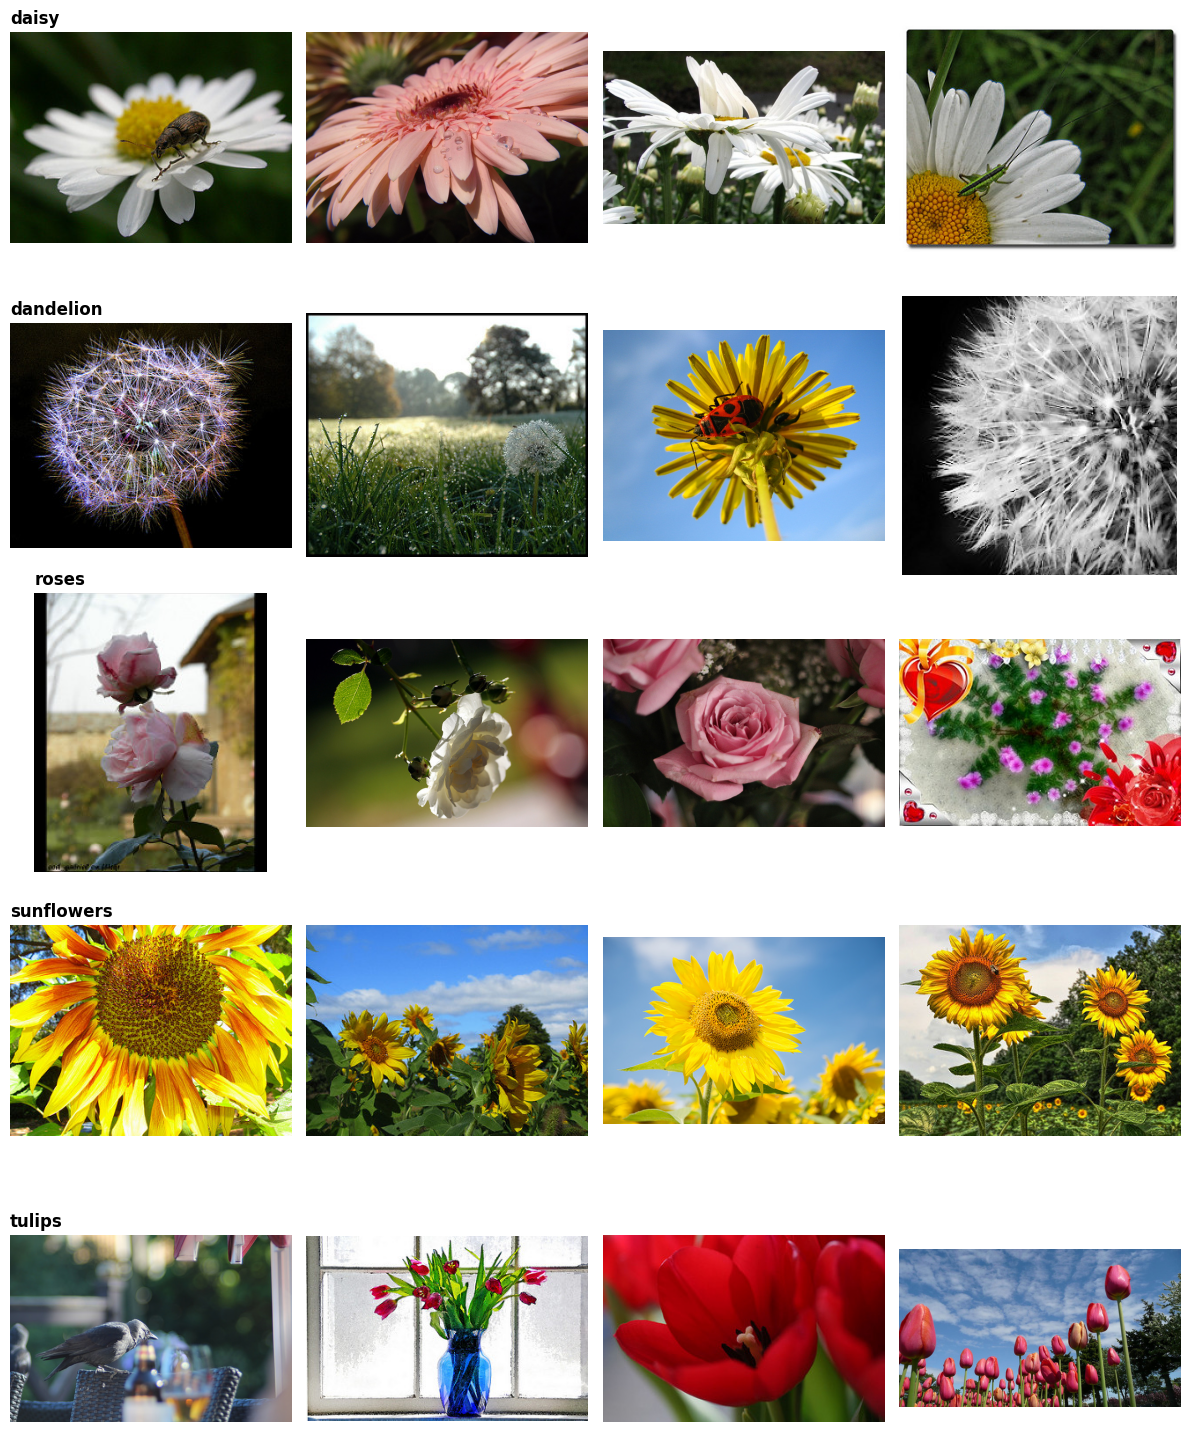

In [5]:
# (b) Ejemplos por clase (4 por clase)
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(NUM_CLASSES, 4, figsize=(12, 3 * NUM_CLASSES))
for r, name in enumerate(class_names):
    idxs = rng.choice(np.where(labels == r)[0], 4, replace=False)
    for c, i in enumerate(idxs):
        axes[r, c].imshow(Image.open(paths[i]).convert("RGB"))
        axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_title(name, loc="left", fontsize=12, fontweight="bold")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "ejemplos_por_clase.png", dpi=120); plt.show()

Imágenes ilegibles/corruptas: 0
Ancho  -> min 143, mediana 320, max 1024
Alto   -> min 159, mediana 240, max 442
Tamaños distintos: 345


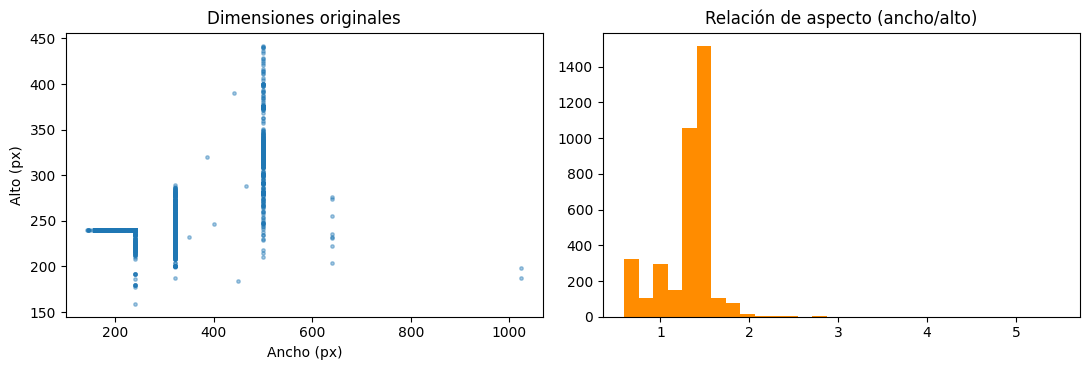

In [6]:
# (c) Tamaños de imagen y (d) integridad (solo se lee la cabecera, es rápido)
sizes, corrupt = [], []
for p in paths:
    try:
        with Image.open(p) as im:
            sizes.append(im.size)   # (ancho, alto)
    except Exception:
        corrupt.append(p)
sizes = np.array(sizes)
print(f"Imágenes ilegibles/corruptas: {len(corrupt)}")
print(f"Ancho  -> min {sizes[:,0].min()}, mediana {int(np.median(sizes[:,0]))}, max {sizes[:,0].max()}")
print(f"Alto   -> min {sizes[:,1].min()}, mediana {int(np.median(sizes[:,1]))}, max {sizes[:,1].max()}")
print(f"Tamaños distintos: {len({tuple(s) for s in sizes})}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].scatter(sizes[:, 0], sizes[:, 1], s=6, alpha=.4); ax[0].set_xlabel("Ancho (px)"); ax[0].set_ylabel("Alto (px)")
ax[0].set_title("Dimensiones originales")
ax[1].hist(sizes[:, 0] / sizes[:, 1], bins=30, color="darkorange"); ax[1].set_title("Relación de aspecto (ancho/alto)")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "tamanos_imagenes.png", dpi=150); plt.show()

In [7]:
# (e) Estadísticas de píxeles (muestra de 400 imágenes ya redimensionadas)
sample = rng.choice(len(paths), size=min(400, len(paths)), replace=False)
arr = np.stack([np.asarray(Image.open(paths[i]).convert("RGB").resize(IMG_SIZE), dtype="float32") for i in sample])
print("Rango de píxeles :", arr.min(), "-", arr.max())
print("Media por canal  (R,G,B):", arr.mean(axis=(0, 1, 2)).round(1))
print("Desv. por canal  (R,G,B):", arr.std(axis=(0, 1, 2)).round(1))
del arr

Rango de píxeles : 0.0 - 255.0
Media por canal  (R,G,B): [116.4 105.8  74.4]
Desv. por canal  (R,G,B): [75.6 68.5 74. ]


**Observaciones de la exploración**
- Las imágenes **no tienen un tamaño único**, así que es obligatorio redimensionarlas a un tamaño fijo (`180×180`) para poder agruparlas en lotes.
- Los píxeles están en el rango **0–255**; se llevan a **0–1** para estabilizar el entrenamiento.
- Las clases no están perfectamente balanceadas (ver gráfica), por eso además de la *accuracy* se reportan **precisión, recall y F1 por clase** y **F1 macro**.
- Dentro de una misma clase hay mucha variación (ángulo, iluminación, fondo, encuadre), lo que motiva el Data Augmentation.

## 3. Preprocesamiento, normalización y división del dataset

**Pasos del preprocesamiento**
1. Lectura del archivo y decodificación a RGB (3 canales).
2. Redimensionado a `180×180`.
3. **Normalización** `píxel / 255` → rango `[0, 1]`. Esta capa (`Rescaling`) está **dentro del modelo**, de modo que el modelo guardado acepta píxeles 0–255 y la app Streamlit no puede olvidarse de normalizar.

**División:** estratificada (se conserva la proporción de clases en cada subconjunto), con semilla fija: **70 % entrenamiento · 15 % validación · 15 % prueba**.
- *Entrenamiento*: ajusta los pesos.
- *Validación*: guía el entrenamiento (early stopping, ajuste de learning rate).
- *Prueba*: se usa **una sola vez al final** para estimar el desempeño real.

In [8]:
p_train, p_tmp, y_train, y_tmp = train_test_split(
    paths, labels, test_size=VAL_FRAC + TEST_FRAC, stratify=labels, random_state=SEED)
p_val, p_test, y_val, y_test = train_test_split(
    p_tmp, y_tmp, test_size=TEST_FRAC / (VAL_FRAC + TEST_FRAC), stratify=y_tmp, random_state=SEED)

split_table = pd.DataFrame({
    "train": pd.Series(y_train).value_counts().sort_index(),
    "val":   pd.Series(y_val).value_counts().sort_index(),
    "test":  pd.Series(y_test).value_counts().sort_index()})
split_table.index = class_names
split_table.loc["TOTAL"] = split_table.sum()
display(split_table)
print(f"Proporciones -> train {len(p_train)/len(paths):.1%} | val {len(p_val)/len(paths):.1%} | test {len(p_test)/len(paths):.1%}")

,train,val,test
daisy,443,95,95
dandelion,629,134,135
roses,449,96,96
sunflowers,489,105,105
tulips,559,120,120
TOTAL,2569,550,551


Proporciones -> train 70.0% | val 15.0% | test 15.0%


In [9]:
def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)          # float32, rango 0-255
    img.set_shape((*IMG_SIZE, 3))
    return img, label

def make_dataset(p, y, training):
    ds = tf.data.Dataset.from_tensor_slices((p, y))
    if training:
        ds = ds.shuffle(len(p), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(p_train, y_train, training=True)
val_ds   = make_dataset(p_val,   y_val,   training=False)
test_ds  = make_dataset(p_test,  y_test,  training=False)   # sin shuffle: el orden coincide con y_test

xb, yb = next(iter(train_ds))
print("Forma de un lote:", xb.shape, "| etiquetas:", yb.shape)
print("Rango de píxeles del lote:", float(tf.reduce_min(xb)), "-", float(tf.reduce_max(xb)), "(se normaliza dentro del modelo)")

Forma de un lote: (32, 180, 180, 3) | etiquetas: (32,)
Rango de píxeles del lote: 0.0 - 255.0 (se normaliza dentro del modelo)


## 4. Data Augmentation
Con ~2.500 imágenes de entrenamiento, una CNN grande tiende a **memorizar** el set de entrenamiento. El aumento de datos genera variaciones realistas en cada época: volteo horizontal, rotación leve, zoom y contraste.

Estas capas **solo se activan durante el entrenamiento**; en validación, prueba e inferencia (Streamlit) no modifican la imagen.

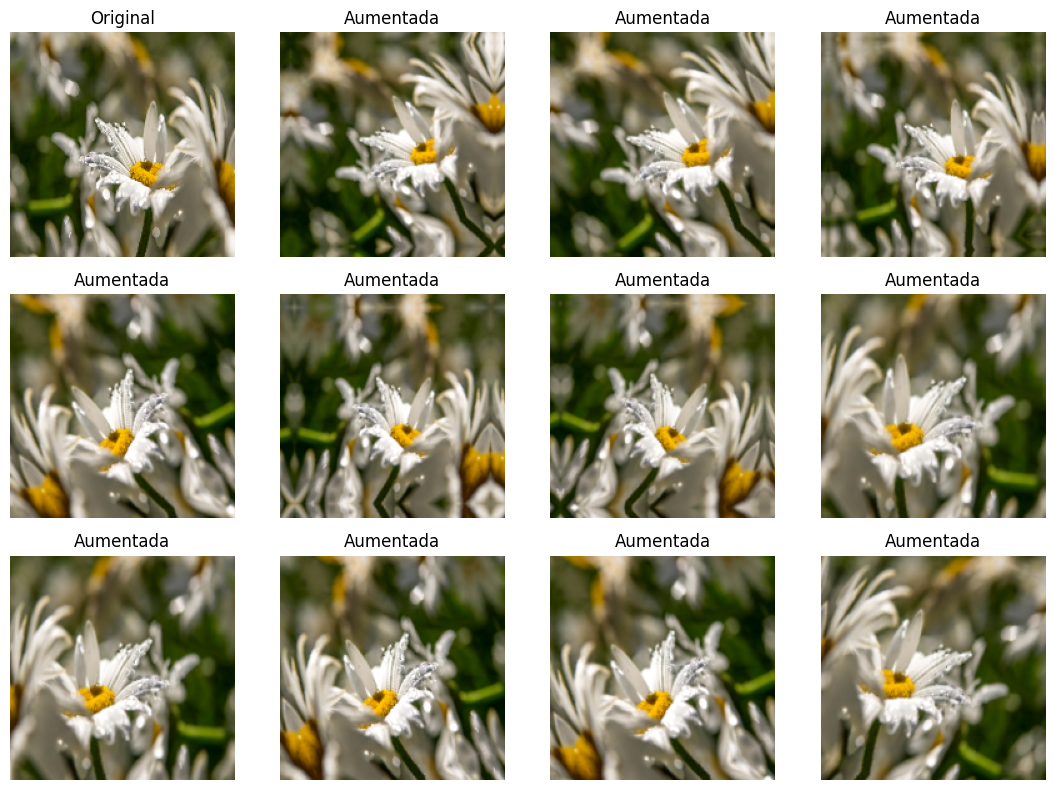

In [10]:
def build_augmentation():
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.10),
        layers.RandomZoom(0.15),
        layers.RandomContrast(0.10),
    ], name="data_augmentation")

# Visualización: misma imagen, 9 versiones aumentadas
aug_demo = build_augmentation()
img0 = xb[0:1] / 255.0
fig, axes = plt.subplots(3, 4, figsize=(11, 8))
axes[0, 0].imshow(img0[0].numpy()); axes[0, 0].set_title("Original")
for ax in axes.ravel()[1:]:
    ax.imshow(np.clip(aug_demo(img0, training=True)[0].numpy(), 0, 1)); ax.set_title("Aumentada")
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "data_augmentation.png", dpi=130); plt.show()

## 5. Construcción de la CNN
Arquitectura (4 bloques convolucionales):

`Entrada 180×180×3 → Rescaling(1/255) → Data Augmentation → [Conv3×3 → BatchNorm → ReLU] ×2 → MaxPool` repetido con **32, 64, 128 y 256** filtros `→ GlobalAveragePooling → Dropout(0.4) → Dense(128, ReLU) → Dropout(0.3) → Dense(5, softmax)`

- **BatchNormalization**: estabiliza y acelera el entrenamiento.
- **GlobalAveragePooling** en lugar de `Flatten`: menos parámetros y menos sobreajuste.
- **Dropout**: regularización adicional.
- **Softmax** en la salida: entrega probabilidades por clase (el nivel de confianza que muestra la app).
- **Pérdida:** `sparse_categorical_crossentropy` (etiquetas enteras). **Optimizador:** Adam.

In [11]:
def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    return layers.MaxPooling2D()(x)

def build_model(num_classes):
    inputs = keras.Input(shape=(*IMG_SIZE, 3), name="imagen")
    x = layers.Rescaling(1.0 / 255, name="normalizacion")(inputs)
    x = build_augmentation()(x)
    for filters in (32, 64, 128, 256):
        x = conv_block(x, filters)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="probabilidades")(x)
    model = keras.Model(inputs, outputs, name="cnn_flores")
    model.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

model = build_model(NUM_CLASSES)
model.summary()

Model: "cnn_flores"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen (InputLayer)             │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalizacion (Rescaling)       │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 180, 180, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 180, 180, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 180, 180, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 180, 180, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 180, 180, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 180, 180, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 90, 90, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 90, 90, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 90, 90, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 90, 90, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 90, 90, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 90, 90, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 45, 45, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 45, 45, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 45, 45, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 45, 45, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 45, 45, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 1,208,677 (4.61 MB)

 Trainable params: 1,206,757 (4.60 MB)

 Non-trainable params: 1,920 (7.50 KB)

## 6. Entrenamiento
- **EarlyStopping** (paciencia 8, monitoriza `val_loss`): detiene el entrenamiento cuando deja de mejorar y **restaura los mejores pesos**.
- **ReduceLROnPlateau**: reduce el learning rate a la mitad si `val_loss` se estanca 3 épocas.

In [12]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5, verbose=1),
]
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks)
hist = {k: [float(v) for v in vals] for k, vals in history.history.items()}

Epoch 1/40
81/81 ━━━━━━━━━━━━━━━━━━━━ 28s 212ms/step - accuracy: 0.4726 - loss: 1.3203 - val_accuracy: 0.2436 - val_loss: 2.0863 - learning_rate: 0.0010
Epoch 2/40
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 195ms/step - accuracy: 0.5496 - loss: 1.1200 - val_accuracy: 0.2727 - val_loss: 2.1733 - learning_rate: 0.0010
Epoch 3/40
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 191ms/step - accuracy: 0.5944 - loss: 0.9974 - val_accuracy: 0.2745 - val_loss: 2.2019 - learning_rate: 0.0010
Epoch 4/40
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 194ms/step - accuracy: 0.6193 - loss: 0.9580 - val_accuracy: 0.4055 - val_loss: 1.8173 - learning_rate: 0.0010
Epoch 5/40
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 200ms/step - accuracy: 0.6415 - loss: 0.9203 - val_accuracy: 0.5509 - val_loss: 1.1328 - learning_rate: 0.0010
Epoch 6/40
81/81 ━━━━━━━━━━━━━━━━━━━━ 20s 196ms/step - accuracy: 0.6532 - loss: 0.9059 - val_accuracy: 0.4873 - val_loss: 1.1249 - learning_rate: 0.0010
Epoch 7/40
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 198ms/step - accuracy: 0.6594 - loss: 0.

## 7. Gráficas del entrenamiento

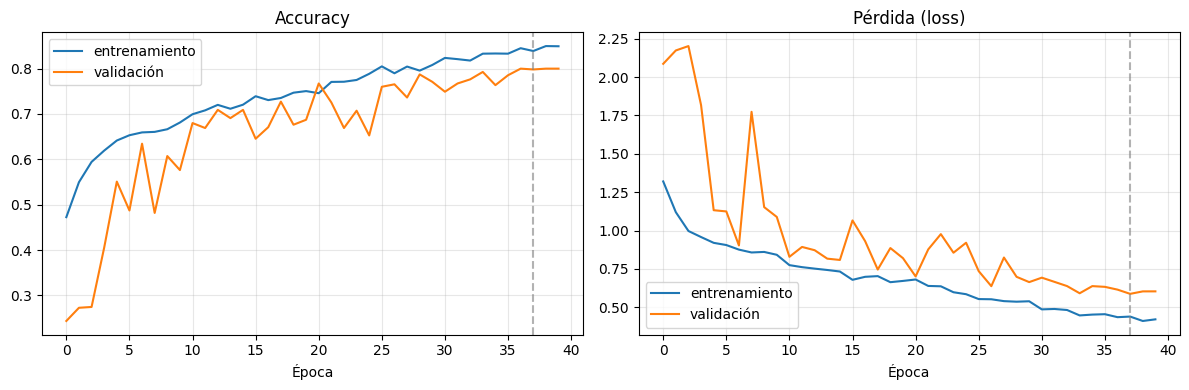

Épocas ejecutadas: 40 | mejor época (menor val_loss): 38
En la mejor época -> train acc 0.8388 | val acc 0.7982


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, key, title in zip(axes, ("accuracy", "loss"), ("Accuracy", "Pérdida (loss)")):
    ax.plot(hist[key], label="entrenamiento"); ax.plot(hist["val_" + key], label="validación")
    ax.set_title(title); ax.set_xlabel("Época"); ax.grid(alpha=.3); ax.legend()
best_ep = int(np.argmin(hist["val_loss"]))
for ax in axes: ax.axvline(best_ep, color="gray", ls="--", alpha=.6)
plt.tight_layout(); plt.savefig(FIGURES_DIR / "curvas_entrenamiento.png", dpi=150); plt.show()

print(f"Épocas ejecutadas: {len(hist['loss'])} | mejor época (menor val_loss): {best_ep + 1}")
print(f"En la mejor época -> train acc {hist['accuracy'][best_ep]:.4f} | val acc {hist['val_accuracy'][best_ep]:.4f}")

## 8. Evaluación con métricas apropiadas
Se evalúa sobre el **conjunto de prueba**, que el modelo no usó ni para entrenar ni para ajustar el entrenamiento.

Métricas:
- **Accuracy**: porcentaje total de aciertos.
- **Precisión, recall y F1 por clase**: necesarias porque las clases no están perfectamente balanceadas y la accuracy sola puede ocultar clases con mal desempeño.
- **F1 macro**: promedio de F1 que trata todas las clases por igual.
- **Matriz de confusión**: muestra qué clases se confunden entre sí.

In [14]:
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
probs  = model.predict(test_ds, verbose=0)
y_pred = probs.argmax(axis=1)
macro_f1 = f1_score(y_test, y_pred, average="macro")

print(f"Test loss     : {test_loss:.4f}")
print(f"Test accuracy : {test_acc:.4f}")
print(f"Macro F1      : {macro_f1:.4f}\n")
print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))
report = classification_report(y_test, y_pred, target_names=class_names, output_dict=True, zero_division=0)

Test loss     : 0.5612
Test accuracy : 0.8004
Macro F1      : 0.7971

              precision    recall  f1-score   support

       daisy       0.85      0.72      0.78        95
   dandelion       0.88      0.79      0.83       135
       roses       0.75      0.72      0.73        96
  sunflowers       0.82      0.91      0.86       105
      tulips       0.72      0.84      0.78       120

    accuracy                           0.80       551
   macro avg       0.80      0.80      0.80       551
weighted avg       0.81      0.80      0.80       551



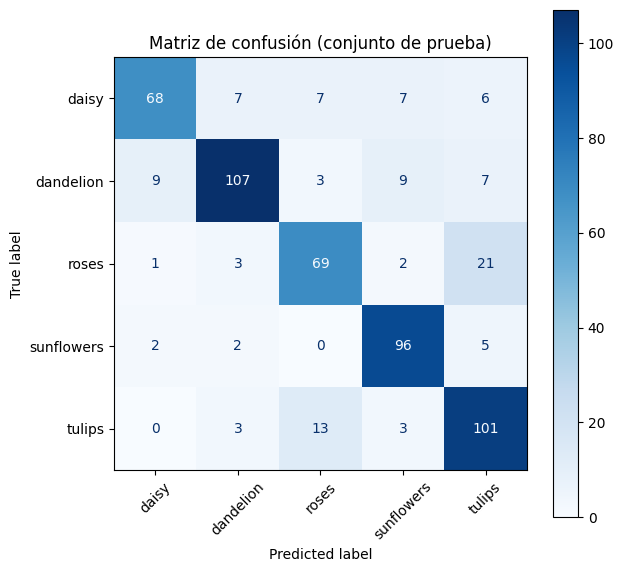

Confusiones más frecuentes (real -> predicho):
       roses -> tulips    : 21
      tulips -> roses     : 13
   dandelion -> sunflowers: 9
   dandelion -> daisy     : 9
   dandelion -> tulips    : 7


In [15]:
fig, ax = plt.subplots(figsize=(6.5, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=class_names,
                                        cmap="Blues", ax=ax, xticks_rotation=45)
ax.set_title("Matriz de confusión (conjunto de prueba)")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "matriz_confusion.png", dpi=150); plt.show()

# Confusiones más frecuentes (fuera de la diagonal)
cm = confusion_matrix(y_test, y_pred)
off = [(cm[i, j], class_names[i], class_names[j]) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j and cm[i, j] > 0]
print("Confusiones más frecuentes (real -> predicho):")
for n, a, b in sorted(off, reverse=True)[:5]:
    print(f"  {a:>10} -> {b:<10}: {n}")

## 9. Predicciones con imágenes (12 del conjunto de prueba)
Verde = acierto · Rojo = error. Se muestra la clase predicha y su probabilidad.

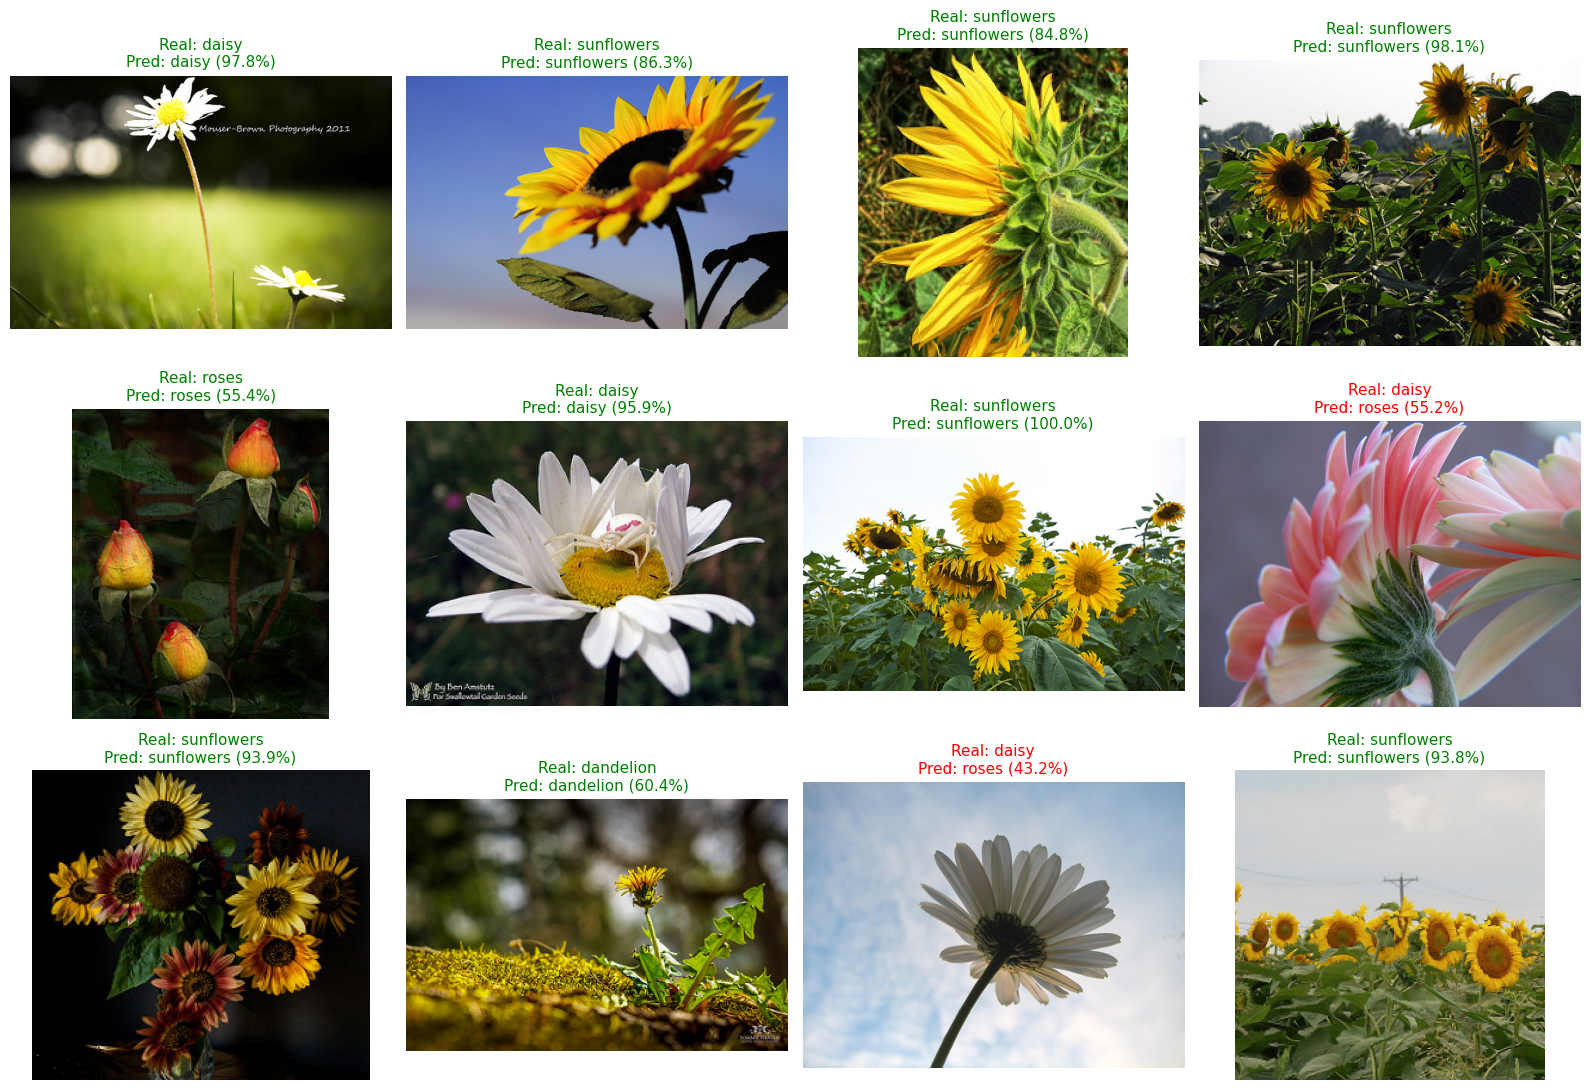

,imagen,real,predicha,confianza_%,acierto
0,5876455546_32049e5585.jpg,daisy,daisy,97.76,True
1,2996573407_5e473b9359.jpg,sunflowers,sunflowers,86.32,True
2,14678298676_6db8831ee6_m.jpg,sunflowers,sunflowers,84.77,True
3,2328600790_90e2942557_n.jpg,sunflowers,sunflowers,98.05,True
4,6039330368_c30ed224c4_m.jpg,roses,roses,55.40,True
5,16482676953_5296227d40_n.jpg,daisy,daisy,95.94,True
6,9535500195_543d0b729b.jpg,sunflowers,sunflowers,99.99,True
7,512177035_70afc925c8.jpg,daisy,roses,55.18,False
8,15207507116_8b7f894508_m.jpg,sunflowers,sunflowers,93.89,True
9,14373114081_7922bcf765_n.jpg,dandelion,dandelion,60.41,True


In [16]:
idx = np.random.default_rng(SEED).choice(len(p_test), size=12, replace=False)
fig, axes = plt.subplots(3, 4, figsize=(16, 11))
rows = []
for ax, i in zip(axes.ravel(), idx):
    pred = int(np.argmax(probs[i])); conf = float(probs[i][pred]); ok = pred == int(y_test[i])
    ax.imshow(Image.open(p_test[i]).convert("RGB")); ax.axis("off")
    ax.set_title(f"Real: {class_names[y_test[i]]}\nPred: {class_names[pred]} ({conf*100:.1f}%)",
                 color="green" if ok else "red", fontsize=11)
    rows.append({"imagen": Path(p_test[i]).name, "real": class_names[y_test[i]],
                 "predicha": class_names[pred], "confianza_%": round(conf * 100, 2), "acierto": ok})
plt.tight_layout(); plt.savefig(FIGURES_DIR / "predicciones_12.png", dpi=130); plt.show()
display(pd.DataFrame(rows))

Errores en test: 110 de 551


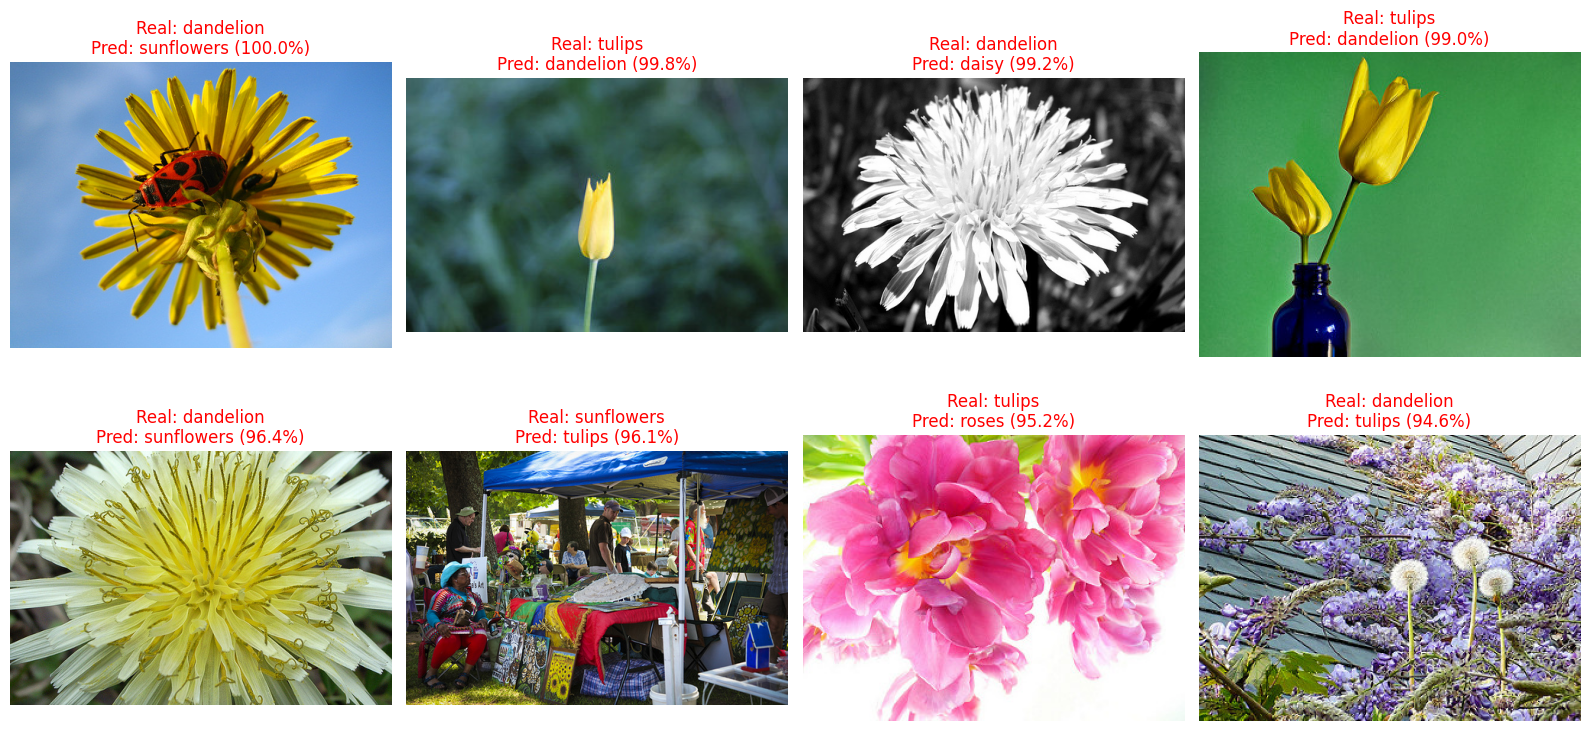

In [17]:
# Ejemplos que el modelo clasificó MAL (análisis de errores)
wrong = np.where(y_pred != y_test)[0]
print(f"Errores en test: {len(wrong)} de {len(y_test)}")
if len(wrong):
    show = wrong[np.argsort(-probs[wrong].max(axis=1))][:8]    # los errores con mayor confianza
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    for ax in axes.ravel(): ax.axis("off")
    for ax, i in zip(axes.ravel(), show):
        pred = int(np.argmax(probs[i]))
        ax.imshow(Image.open(p_test[i]).convert("RGB"))
        ax.set_title(f"Real: {class_names[y_test[i]]}\nPred: {class_names[pred]} ({probs[i][pred]*100:.1f}%)", color="red")
    plt.tight_layout(); plt.savefig(FIGURES_DIR / "errores.png", dpi=120); plt.show()

## 10. Guardado del modelo
Se guarda el modelo completo (arquitectura + pesos + normalización) en formato `.keras`, junto con los nombres de clase, el historial y las métricas. La app Streamlit carga exactamente estos archivos.

In [18]:
model.save(MODEL_PATH)
CLASS_NAMES_PATH.write_text(json.dumps(class_names, ensure_ascii=False, indent=2))
(REPORTS_DIR / "history.json").write_text(json.dumps(hist, indent=2))
(REPORTS_DIR / "metrics.json").write_text(json.dumps({
    "test_loss": float(test_loss), "test_accuracy": float(test_acc), "macro_f1": float(macro_f1),
    "n_test": int(len(y_test)), "classification_report": report,
    "versions": {"tensorflow": tf.__version__, "keras": keras.__version__, "python": sys.version.split()[0]},
}, indent=2))
print("Modelo guardado:", MODEL_PATH, f"({MODEL_PATH.stat().st_size / 1e6:.1f} MB)")

# Verificación: el modelo recargado debe dar las mismas predicciones
reloaded = keras.models.load_model(MODEL_PATH)
xb_t, _ = next(iter(test_ds))
diff = np.abs(reloaded.predict(xb_t, verbose=0) - model.predict(xb_t, verbose=0)).max()
print(f"Diferencia máxima entre modelo original y recargado: {diff:.2e}")
assert diff < 1e-4, "El modelo recargado no coincide con el original"

Modelo guardado: /content/models/flower_cnn.keras (14.6 MB)
Diferencia máxima entre modelo original y recargado: 0.00e+00


In [19]:
# Predicción individual con el modelo recargado, simulando lo que hace la app Streamlit
def predict_pil(img):
    img = tf.image.resize(np.asarray(img.convert("RGB"), dtype="float32"), IMG_SIZE).numpy()[None]
    pr = reloaded.predict(img, verbose=0)[0]
    return class_names[int(pr.argmax())], float(pr.max())

clase, conf = predict_pil(Image.open(p_test[0]))
print(f"Real: {class_names[y_test[0]]} | Predicha: {clase} | Confianza: {conf*100:.2f}%")

Real: roses | Predicha: roses | Confianza: 93.94%


In [20]:
# Empaquetar los resultados de Colab para descargarlos y subirlos al repositorio
zip_path = BASE / "resultados_colab.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for folder in (MODELS_DIR, REPORTS_DIR):
        for f in folder.rglob("*"):
            if f.is_file():
                z.write(f, f.relative_to(BASE))
print("Creado:", zip_path)
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    print("(No estás en Colab: los archivos ya están en models/ y reports/)")

Creado: /content/resultados_colab.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Resumen automático de resultados
La siguiente celda redacta el resumen con los **valores reales** obtenidos en esta ejecución.

In [21]:
f1s = {c: report[c]["f1-score"] for c in class_names}
best_c, worst_c = max(f1s, key=f1s.get), min(f1s, key=f1s.get)
gap = hist["accuracy"][best_ep] - hist["val_accuracy"][best_ep]
print(f"""RESULTADOS FINALES
- Imágenes: {len(paths)} (train {len(p_train)}, val {len(p_val)}, test {len(p_test)})
- Épocas ejecutadas: {len(hist['loss'])}; mejor época: {best_ep + 1}
- Accuracy en test: {test_acc*100:.2f}%  |  F1 macro: {macro_f1*100:.2f}%
- Mejor clase (F1): {best_c} = {f1s[best_c]:.3f}  |  Peor clase (F1): {worst_c} = {f1s[worst_c]:.3f}
- Brecha train-val en la mejor época: {gap*100:+.2f} puntos de accuracy
  (train {hist['accuracy'][best_ep]*100:.2f}% vs val {hist['val_accuracy'][best_ep]*100:.2f}%)
""")

RESULTADOS FINALES
- Imágenes: 3670 (train 2569, val 550, test 551)
- Épocas ejecutadas: 40; mejor época: 38
- Accuracy en test: 80.04%  |  F1 macro: 79.71%
- Mejor clase (F1): sunflowers = 0.865  |  Peor clase (F1): roses = 0.734
- Brecha train-val en la mejor época: +4.07 puntos de accuracy
  (train 83.88% vs val 79.82%)



## 12. Conclusiones y limitaciones

**Conclusiones**
- Se construyó una CNN desde cero con normalización integrada, Data Augmentation, BatchNorm y Dropout, entrenada con early stopping y ajuste de learning rate. Las cifras finales (accuracy, F1, mejor y peor clase, brecha train-val) están en el resumen automático de la sección anterior y en `reports/metrics.json`.
- La **matriz de confusión** y el **análisis de errores** muestran qué clases se confunden; suelen coincidir con flores de apariencia o fondo similares.
- Incluir las capas de preprocesamiento **dentro del modelo** garantiza que la app Streamlit aplique exactamente la misma normalización que el entrenamiento.

**Limitaciones**
- El modelo solo conoce **5 clases**: ante una imagen que no es una de ellas igualmente devolverá una de las 5. Por eso la app avisa cuando la confianza es baja.
- Las fotos son de tamaño reducido (`180×180`) y el dataset es pequeño, lo que limita la precisión máxima de una CNN entrenada desde cero.

**Mejoras futuras**
- *Transfer learning* (p. ej. MobileNetV2 o EfficientNet preentrenadas en ImageNet).
- Una clase "otro/no es flor" para rechazar imágenes fuera de dominio.
- Búsqueda sistemática de hiperparámetros y validación cruzada.